<a href="https://colab.research.google.com/github/IstaftyKevaYuftika/pm-turi4-clustering/blob/main/PM_P9_IstaftyKevaYuftika_2488010007_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Pertemuan 9 — Clustering dengan K-Means

**Mata kuliah:** Pembelajaran Mesin  
**Topik:** Segmentasi pelanggan menggunakan fitur usia, pendapatan, dan skor belanja.

Notebook ini mengikuti langkah pada modul: menyiapkan data tanpa label, scaling, metode Elbow, K-Means (K=3), evaluasi silhouette, interpretasi cluster, latihan mandiri, dan refleksi.

## 1. Import library dan menyiapkan dataset

dataset pelanggan buatan dengan fitur `usia`, `pendapatan`, dan `skor_belanja`, tetapi tidak menyertakan file dataset. Karena itu, sel berikut membuat **data sintetis** agar notebook dapat langsung dijalankan.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Membuat data pelanggan sintetis dengan 3 kelompok yang berbeda.
# random_state menjaga hasil agar dapat direproduksi.
rng = np.random.default_rng(42)

kelompok_1 = np.column_stack([
    rng.normal(23, 4, 50),       # usia
    rng.normal(4_000_000, 700_000, 50),  # pendapatan
    rng.normal(75, 10, 50)       # skor belanja
])
kelompok_2 = np.column_stack([
    rng.normal(40, 5, 50),
    rng.normal(8_000_000, 1_000_000, 50),
    rng.normal(45, 10, 50)
])
kelompok_3 = np.column_stack([
    rng.normal(55, 6, 50),
    rng.normal(12_000_000, 1_500_000, 50),
    rng.normal(25, 8, 50)
])

data = np.vstack([kelompok_1, kelompok_2, kelompok_3])
df = pd.DataFrame(data, columns=['usia', 'pendapatan', 'skor_belanja'])

# Rapikan nilai ke rentang yang masuk akal
df['usia'] = df['usia'].round().clip(18, 75).astype(int)
df['pendapatan'] = df['pendapatan'].round().clip(1_000_000, None).astype(int)
df['skor_belanja'] = df['skor_belanja'].round().clip(1, 100).astype(int)

display(df.head())
print('Ukuran dataset:', df.shape)
print('Nilai kosong per kolom:')
display(df.isna().sum())

,usia,pendapatan,skor_belanja
0,24,4202384,71
1,19,4441902,88
2,26,2979991,71
3,27,3776230,82
4,18,3670739,66


Ukuran dataset: (150, 3)
Nilai kosong per kolom:


,0
usia,0
pendapatan,0
skor_belanja,0


## 2. Scaling data
K-Means berbasis jarak. StandardScaler menyetarakan skala fitur agar pendapatan yang memiliki angka jauh lebih besar tidak mendominasi perhitungan jarak.

In [ ]:
fitur = ['usia', 'pendapatan', 'skor_belanja']
X = df[fitur]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print('Rata-rata fitur setelah scaling (mendekati 0):', X_scaled.mean(axis=0).round(3))
print('Standar deviasi setelah scaling (mendekati 1):', X_scaled.std(axis=0).round(3))

Rata-rata fitur setelah scaling (mendekati 0): [ 0. -0. -0.]
Standar deviasi setelah scaling (mendekati 1): [1. 1. 1.]


## 3. Metode Elbow untuk menentukan K
Grafik inertia menunjukkan jumlah kuadrat jarak anggota cluster ke centroid. Pilih nilai K di titik ketika penurunan inertia mulai melambat (titik siku).

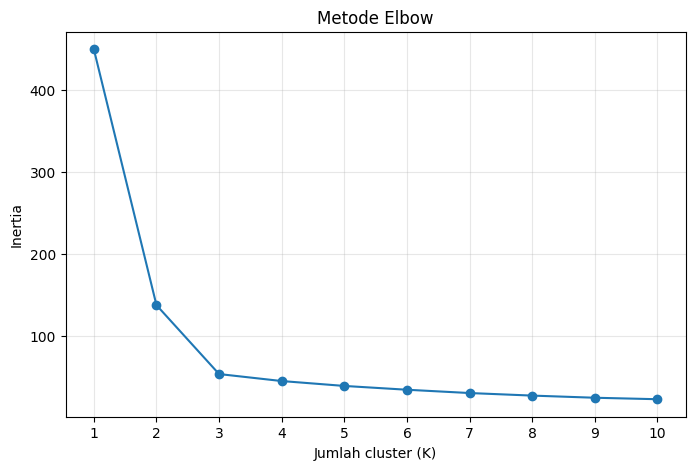

In [ ]:
inertias = []
rentang_k = range(1, 11)

for k in rentang_k:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(rentang_k), inertias, marker='o')
plt.xticks(list(rentang_k))
plt.xlabel('Jumlah cluster (K)')
plt.ylabel('Inertia')
plt.title('Metode Elbow')
plt.grid(True, alpha=0.3)
plt.show()

**Pengamatan:** Pada data sintetis ini, K sekitar 3 diharapkan menjadi pilihan yang masuk akal karena data dibuat dari tiga kelompok. Namun, penentuan K tetap perlu mempertimbangkan bentuk grafik dan karakteristik data yang digunakan.

## 4. Menjalankan K-Means dengan K=3

In [ ]:
kmeans3 = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans3.fit_predict(X_scaled)

print('Jumlah anggota setiap cluster:')
display(df['cluster'].value_counts().sort_index().rename('jumlah_anggota').to_frame())

Jumlah anggota setiap cluster:


,jumlah_anggota
cluster,
0,51
1,50
2,49


## 5. Evaluasi dengan silhouette score
Silhouette berada pada rentang -1 sampai 1. Nilai yang lebih tinggi umumnya menunjukkan cluster yang lebih kompak dan terpisah dengan baik.

In [ ]:
silhouette_k3 = silhouette_score(X_scaled, df['cluster'])
print(f'Silhouette score untuk K=3: {silhouette_k3:.3f}')

Silhouette score untuk K=3: 0.596


## 6. Interpretasi profil rata-rata tiap cluster
Nomor cluster hanyalah label dari algoritma; cluster 0 tidak otomatis lebih baik atau lebih buruk daripada cluster lain. Gunakan nilai rata-rata fitur untuk memberi nama yang deskriptif.

In [ ]:
profil = df.groupby('cluster')[fitur].mean().round(1)
print('Profil rata-rata tiap cluster:')
display(profil)

# Nama deskriptif dibuat berdasarkan perbandingan profil pada hasil aktual.
for nomor, baris in profil.iterrows():
    if baris['skor_belanja'] >= profil['skor_belanja'].quantile(0.67):
        nama = 'Skor belanja relatif tinggi'
    elif baris['skor_belanja'] <= profil['skor_belanja'].quantile(0.33):
        nama = 'Skor belanja relatif rendah'
    else:
        nama = 'Skor belanja menengah'
    print(f'Cluster {nomor}: {nama}; rata-rata usia {baris["usia"]:.1f}, '
          f'pendapatan {baris["pendapatan"]:,.1f}, '
          f'skor belanja {baris["skor_belanja"]:.1f}.')

Profil rata-rata tiap cluster:


,usia,pendapatan,skor_belanja
cluster,,,
0,55.7,12120444.5,24.4
1,23.5,3865774.8,74.4
2,40.1,7776323.7,45.1


Cluster 0: Skor belanja relatif rendah; rata-rata usia 55.7, pendapatan 12,120,444.5, skor belanja 24.4.
Cluster 1: Skor belanja relatif tinggi; rata-rata usia 23.5, pendapatan 3,865,774.8, skor belanja 74.4.
Cluster 2: Skor belanja menengah; rata-rata usia 40.1, pendapatan 7,776,323.7, skor belanja 45.1.


## 7. Latihan mandiri 6 — Bandingkan K=5 dengan K=3

In [ ]:
kmeans5 = KMeans(n_clusters=5, random_state=42, n_init=10)
label_k5 = kmeans5.fit_predict(X_scaled)
silhouette_k5 = silhouette_score(X_scaled, label_k5)

perbandingan = pd.DataFrame({
    'K': [3, 5],
    'Silhouette score': [silhouette_k3, silhouette_k5]
})
display(perbandingan)

if silhouette_k3 > silhouette_k5:
    print('Kesimpulan: pada data ini, K=3 memiliki silhouette score lebih tinggi daripada K=5.')
elif silhouette_k5 > silhouette_k3:
    print('Kesimpulan: pada data ini, K=5 memiliki silhouette score lebih tinggi daripada K=3.')
else:
    print('Kesimpulan: kedua nilai silhouette score sama.')

,K,Silhouette score
0,3,0.595852
1,5,0.381122


Kesimpulan: pada data ini, K=3 memiliki silhouette score lebih tinggi daripada K=5.


## 8. Latihan mandiri 7 — K-Means tanpa scaling
Percobaan ini memakai fitur asli. Karena skala pendapatan jauh lebih besar daripada usia dan skor belanja, jarak dapat lebih banyak dipengaruhi oleh pendapatan.

In [ ]:
kmeans_raw = KMeans(n_clusters=3, random_state=42, n_init=10)
label_raw = kmeans_raw.fit_predict(df[fitur])
silhouette_raw = silhouette_score(df[fitur], label_raw)

display(pd.DataFrame({
    'Percobaan': ['Dengan scaling (K=3)', 'Tanpa scaling (K=3)'],
    'Silhouette score': [silhouette_k3, silhouette_raw]
}))

print('Kesimpulan: bandingkan kedua skor. Scaling penting karena K-Means menggunakan jarak; tanpa scaling, fitur dengan rentang angka besar dapat mendominasi pembentukan cluster.')

,Percobaan,Silhouette score
0,Dengan scaling (K=3),0.595852
1,Tanpa scaling (K=3),0.697496


Kesimpulan: bandingkan kedua skor. Scaling penting karena K-Means menggunakan jarak; tanpa scaling, fitur dengan rentang angka besar dapat mendominasi pembentukan cluster.


## 9. Latihan mandiri 8 — Scatter plot usia vs skor belanja

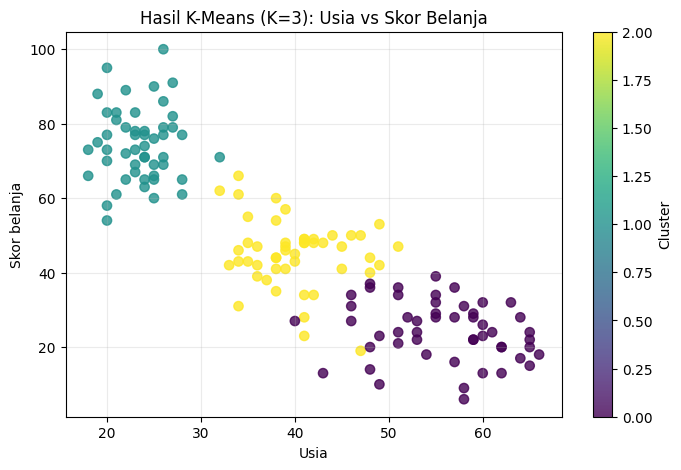

In [ ]:
plt.figure(figsize=(8, 5))
scatter = plt.scatter(
    df['usia'], df['skor_belanja'],
    c=df['cluster'], cmap='viridis', s=45, alpha=0.8
)
plt.xlabel('Usia')
plt.ylabel('Skor belanja')
plt.title('Hasil K-Means (K=3): Usia vs Skor Belanja')
plt.colorbar(scatter, label='Cluster')
plt.grid(True, alpha=0.25)
plt.show()

## 10. Refleksi

**9. Bagaimana K-Means menemukan kelompok tanpa label?**  
K-Means memulai dengan menentukan centroid, menempatkan setiap data ke centroid terdekat, lalu menghitung ulang centroid berdasarkan rata-rata anggota. Langkah penempatan dan pembaruan diulang sampai hasilnya stabil. Proses ini tidak memerlukan label kelas.

**10. Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?**  
Pada data sintetis yang dibuat dari tiga kelompok, penambahan cluster sampai sekitar K=3 mengurangi inertia secara berarti. Setelah itu, penurunan inertia biasanya mulai melambat. Bentuk siku yang sebenarnya tetap harus dilihat pada grafik hasil eksekusi.

**11. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?**  
Scaling menyetarakan skala fitur sebelum jarak dihitung. Tanpa scaling, fitur berangka besar seperti pendapatan dapat mendominasi jarak dibanding usia dan skor belanja, sehingga hasil cluster lebih banyak mencerminkan fitur tersebut.